# trosna-gisteresis: воспроизведение графиков и результатов статьи

Ноутбук воспроизводит все графики и численные результаты статьи А. О. Ферубко, О. Д. Казаков
«Гистерезисное правило перераспределения памяти виртуальных машин с выдержкой времени и периодом
охлаждения» (журнал «Автоматика, связь, информатика»). Правило реализовано в библиотеке
[trosna-gisteresis](https://github.com/89605502155/trosna-gisteresis) (`pip install trosna-gisteresis`).

| В статье | Раздел ноутбука |
|---|---|
| Рис. 5. Временная диаграмма | [1](#1.-Временная-диаграмма-(рис.-5)) |
| Табл. 1. Результаты сравнения правил | [3](#3.-Сравнение-правил-(табл.-1)) |
| Рис. 6. Фрагмент прогона модели | [4](#4.-Фрагмент-прогона-модели-(рис.-6)) |
| Влияние выдержки $T_d$ и времени взведения $T_r$ (числа в тексте) | [5](#5.-Влияние-выдержки-и-времени-взведения) |
| Отметки времени Unix и время обработки точки (раздел «Программная реализация») | [6](#6.-Отметки-времени-Unix-и-время-обработки-точки) |
| Сверка всех чисел со статьёй | [7](#7.-Сверка-со-статьёй) |

Рис. 1–4 в статье являются схемами (контур управления, граф состояний, отсчёт выдержки, алгоритм правила),
а не графиками данных, поэтому здесь не строятся.

Нагрузка виртуальных машин порождается с фиксированными зёрнами, поэтому результаты совпадают со статьёй.
Время обработки одной точки зависит от процессора и версии Python и совпадает со статьёй только по порядку величины.

In [1]:
# Если библиотеки ещё не установлены, раскомментируйте:
# %pip install trosna-gisteresis==0.1.0 matplotlib pandas

## 0. Подготовка

In [2]:
import platform
import time
from dataclasses import dataclass
from importlib.metadata import version

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

from trosna_gisteresis import Hysteresis, HysteresisParams, hysteresis

%matplotlib inline

for pkg in ("trosna-gisteresis", "numpy", "matplotlib", "pandas"):
    print(f"{pkg:18s} {version(pkg)}")
print(f"{'python':18s} {platform.python_version()}")

trosna-gisteresis  0.1.0
numpy              2.5.4
matplotlib         3.11.2
pandas             3.0.6
python             3.12.13


Оформление графиков как в статье: шрифт Times New Roman (если он установлен, иначе DejaVu Serif), кегль 10,
ширина рисунка 115 мм.

In [3]:
CM = 1 / 2.54  # размеры рисунков заданы в сантиметрах, как в статье
FONT = "Times New Roman" if any(f.name == "Times New Roman" for f in font_manager.fontManager.ttflist) else "DejaVu Serif"
mpl.rcParams.update({"figure.dpi": 150, "font.family": FONT, "mathtext.fontset": "stix", "font.size": 10,
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "lines.linewidth": 1.0, "legend.frameon": False})
GRAY, BLUE, RED, GREEN, ORANGE = "0.35", "#24415E", "#B03A2E", "#1E7A3C", "#9A6414"

## 1. Временная диаграмма (рис. 5)

Модельный ряд индекса неравномерности $I_k$ с шагом 5 с: кратковременный выброс (15 с), длительный дисбаланс,
после решения индекс остаётся между порогами, затем новое превышение. Параметры: $\theta^{+} = 0{,}12$,
$\theta^{-} = 0{,}06$, $T_d = 30$ с, $T_c = 60$ с. Правило (4)–(7) сравнивается с правилом с взведением
по времени (9) при $T_r = 150$ с. Функция `hysteresis` библиотеки обрабатывает весь ряд сразу и возвращает
моменты решений, время превышения $d_k$ и флаг готовности $g_k$.

In [4]:
t = np.arange(0.0, 400.0, 5.0)
i = np.full(t.size, 0.03)
i[(t >= 30) & (t < 45)] = 0.20  # короткоживущий процесс
i[(t >= 80) & (t < 150)] = 0.22  # длительная нагрузка
i[(t >= 150) & (t < 230)] = 0.09  # перераспределение не устранило дисбаланс
i[(t >= 230) & (t < 330)] = 0.18
rng = np.random.default_rng(3)
i = i + rng.normal(0, 0.006, t.size)
kw = {"upper": 0.12, "lower": 0.06, "dwell": 30.0, "cooldown": 60.0}
base = hysteresis(i, t, **kw)
ext = hysteresis(i, t, **kw, rearm_after=150.0)
print("решения по (4)-(7):     ", base.fire_times)
print("решения по (4)-(7), (9):", ext.fire_times)

решения по (4)-(7):      [105.]
решения по (4)-(7), (9): [105. 255.]


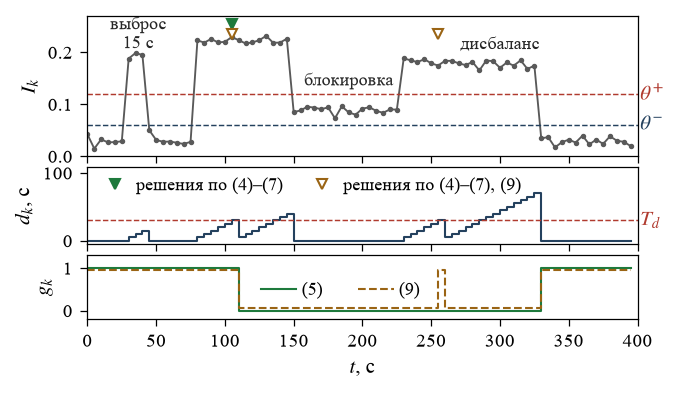

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11.5 * CM, 6.3 * CM), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.2, 1.0], "hspace": 0.12})
ax = axes[0]
ax.plot(t, i, color=GRAY, lw=0.9, marker="o", ms=1.6)
ax.axhline(kw["upper"], color=RED, ls="--", lw=0.7)
ax.axhline(kw["lower"], color=BLUE, ls="--", lw=0.7)
ax.text(402, kw["upper"], "$\\theta^{+}$", va="center", color=RED)
ax.text(402, kw["lower"], "$\\theta^{-}$", va="center", color=BLUE)
for tf in base.fire_times:
    ax.plot(tf, 0.255, "v", color=GREEN, ms=5)
for tf in ext.fire_times:
    ax.plot(tf, 0.235, "v", color=ORANGE, ms=5, mfc="white")
ax.set_ylim(0, 0.27)
ax.set_ylabel("$I_k$")
note = {"fontsize": 8.5, "ha": "center", "va": "center", "color": "0.15"}
ax.text(37, 0.235, "выброс\n15 с", **note)
ax.text(190, 0.145, "блокировка", **note)
ax.text(300, 0.215, "дисбаланс", **note)
h1, = axes[1].plot([], [], "v", color=GREEN, ms=5, label="решения по (4)–(7)")
h2, = axes[1].plot([], [], "v", color=ORANGE, ms=5, mfc="white", label="решения по (4)–(7), (9)")
axes[1].step(t, ext.dwell, where="post", color=BLUE)
axes[1].axhline(kw["dwell"], color=RED, ls="--", lw=0.7)
axes[1].text(402, kw["dwell"], "$T_d$", va="center", color=RED)
axes[1].set_ylabel("$d_k$, с")
axes[1].set_ylim(-5, 108)
axes[1].legend(handles=[h1, h2], loc="upper left", fontsize=8.5, handletextpad=0.2, borderaxespad=0.15,
               ncol=2, columnspacing=1.2)
axes[2].step(t, base.armed.astype(int), where="post", color=GREEN, label="(5)")
axes[2].step(t, ext.armed.astype(int) * 0.9 + 0.05, where="post", color=ORANGE, ls="--", label="(9)")
axes[2].set_yticks([0, 1])
axes[2].set_ylim(-0.2, 1.3)
axes[2].set_ylabel("$g_k$")
axes[2].set_xlabel("$t$, с")
axes[2].legend(loc="center", bbox_to_anchor=(0.46, 0.45), fontsize=8.5, ncol=2, handletextpad=0.3,
               borderaxespad=0.0)
for ax in axes:
    ax.set_xlim(0, 400)
    ax.tick_params(labelsize=9)
fig.subplots_adjust(left=0.12, right=0.93, top=0.98, bottom=0.165)
plt.show()

## 2. Имитационная модель сервера

На сервере 4 ВМ объёмом 2, 4, 4 и 8 ГБ. Занятая ОП каждой ВМ складывается из фоновой составляющей
(40 % объёма ВМ с авторегрессионным шумом), длительных нагрузок (сотни секунд) и короткоживущих процессов
(секунды). Нагрузка порождается заранее для каждого зерна и одинакова для всех сравниваемых правил.
В точке мониторинга вычисляется индекс неравномерности (2), то есть коэффициент вариации долей свободной ОП,
и по нему правило принимает решение. Решение выравнивает доли свободной ОП с учётом нижней и верхней границ
объёма ОП каждой ВМ. Интервал до следующей точки мониторинга выбирается по числу решений в последних пяти
точках: от 10 с при отсутствии решений до 1 с при решениях во всех пяти точках.

Классы решений:
* **обоснованное**: структурный индекс (без короткоживущих процессов) выше $\theta^{+}$ и перераспределение
  переносит не менее $V_0 = 64$ МБ;
* **бесполезное**: структурный индекс выше $\theta^{+}$, но ограничения не позволяют перенести $V_0$;
* **ложное**: структурный индекс не выше $\theta^{+}$ (реакция на кратковременный выброс).

Эпизод дисбаланса есть интервал не короче 60 с со структурным индексом выше $\theta^{+}$. Эпизод без
обоснованного решения считается пропущенным, а задержка реакции отсчитывается от начала эпизода до первого
обоснованного решения в нём.

In [6]:
N_VM = 4
M0 = np.array([2048.0, 4096.0, 4096.0, 8192.0])  # начальные объёмы ОП ВМ, МБ
O_MIN = np.array([512.0, 768.0, 768.0, 1024.0])  # минимальный объём ОП для устойчивой работы ОС
U_MAX = 1.35 * M0  # верхняя граница (максимальный объём ОП в конфигурации ВМ)
HORIZON = 3 * 3600  # длительность одного прогона, с
RUNS = 30  # число прогонов; для быстрой проверки можно уменьшить (числа тогда разойдутся со статьёй)
V0 = 64.0  # минимальный осмысленный объём переноса, МБ
EPISODE_MIN = 60.0  # минимальная длительность эпизода структурного дисбаланса, с
INTERVAL_BY_COUNT = {0: 10, 1: 8, 2: 6, 3: 4, 4: 2, 5: 1}  # число решений из 5 -> интервал, с

UPPER, LOWER = 0.12, 0.06
DWELL, COOLDOWN, REARM = 30.0, 120.0, 300.0

In [7]:
@dataclass(frozen=True)
class Load:
    base: np.ndarray  # (n, T+1) фоновая занятая ОП, МБ
    sustained: list[tuple[int, int, int, float]]  # (вм, начало, конец, объём)
    short: list[tuple[int, int, int, float]]
    full: np.ndarray  # (n, T+1) занятая ОП с учётом всех процессов
    structural: np.ndarray  # (n, T+1) без короткоживущих процессов


def make_load(seed: int) -> Load:
    rng = np.random.default_rng(seed)
    T = HORIZON + 1
    base = np.empty((N_VM, T))
    noise = np.zeros(N_VM)
    level = 0.4 * M0
    for k in range(T):
        noise = 0.9 * noise + rng.normal(0, 0.006, N_VM) * M0
        base[:, k] = level + noise
    sustained, t = [], float(rng.exponential(600))
    while t < HORIZON:
        dur = rng.uniform(300, 900)
        vm = int(rng.integers(N_VM))
        sustained.append((vm, int(t), int(min(t + dur, HORIZON)), float(rng.uniform(0.25, 0.45) * M0[vm])))
        t += dur + rng.exponential(600)
    short = []
    for vm in range(N_VM):
        t = float(rng.exponential(300))
        while t < HORIZON:
            dur = rng.uniform(2, 25)
            short.append((vm, int(t), int(min(t + dur, HORIZON)), float(rng.uniform(0.15, 0.35) * M0[vm])))
            t += dur + rng.exponential(300)
    structural = base.copy()
    for vm, a, b, v in sustained:
        structural[vm, a:b] += v
    full = structural.copy()
    for vm, a, b, v in short:
        full[vm, a:b] += v
    return Load(base, sustained, short, full, structural)


def index(alloc: np.ndarray, used: np.ndarray) -> float:
    # Индекс неравномерности (2): коэффициент вариации долей свободной ОП (1).
    phi = np.clip(alloc - used, 0.0, None) / alloc
    mean = phi.mean()
    return float(phi.std() / mean) if mean > 1e-9 else float("inf")


def equalize(alloc: np.ndarray, used: np.ndarray) -> np.ndarray:
    # Выравнивание долей свободной ОП: m_i = clip(u_i / (1 - lam), L_i, U_i), сумма = M (бисекция по lam).
    total = alloc.sum()
    lower = np.maximum(O_MIN, used)
    upper = np.maximum(U_MAX, lower)
    if lower.sum() > total:
        return alloc  # ОП не хватает даже на минимальные потребности
    lo, hi = 0.0, 1.0 - 1e-9
    for _ in range(60):
        lam = (lo + hi) / 2
        s = np.clip(used / (1 - lam), lower, upper).sum()
        lo, hi = (lo, lam) if s > total else (lam, hi)
    return np.clip(used / (1 - lo), lower, upper)

Сравниваемые правила (обозначения как в табл. 1 статьи):

| Обозначение | Правило |
|---|---|
| А | постоянный порог (3): решение при каждом превышении $\theta$ |
| А′ | один порог с выдержкой и охлаждением, аналог таймера задержки (`rearm_after=0`) |
| Б | два порога без выдержки и охлаждения |
| В | два порога с выдержкой |
| Г | правило (4)–(7), варианты отсчёта выдержки (8а) и (8б) (`dwell_from="sample"`) |
| Д | правило (4)–(7) с взведением по времени (9), варианты (8а) и (8б) |

In [8]:
class ConstantThreshold:
    # Решение при каждом превышении одного порога (правило А).

    def __init__(self, theta: float) -> None:
        self.theta = theta

    def step(self, value: float, t: float) -> bool:
        return value > self.theta


class Rule:
    def __init__(self, params: HysteresisParams) -> None:
        self.h = Hysteresis(params)

    def step(self, value: float, t: float) -> bool:
        return self.h.step(value, t).fired

    @property
    def armed(self) -> bool:
        return self.h.state.armed


def rules(dwell: float = DWELL, cooldown: float = COOLDOWN) -> dict:
    p = HysteresisParams(UPPER, LOWER, dwell, cooldown)
    return {
        "A": lambda: ConstantThreshold(UPPER),
        "A_timer": lambda: Rule(HysteresisParams(UPPER, LOWER, dwell, cooldown, rearm_after=0.0)),
        "B": lambda: Rule(HysteresisParams(UPPER, LOWER, 0.0, 0.0)),
        "C": lambda: Rule(HysteresisParams(UPPER, LOWER, dwell, 0.0)),
        "D": lambda: Rule(p),
        "D_sample": lambda: Rule(HysteresisParams(UPPER, LOWER, dwell, cooldown, dwell_from="sample")),
        "E": lambda: Rule(HysteresisParams(UPPER, LOWER, dwell, cooldown, rearm_after=REARM)),
        "E_sample": lambda: Rule(HysteresisParams(UPPER, LOWER, dwell, cooldown, dwell_from="sample",
                                                  rearm_after=REARM)),
    }


NAMES = {"A": "А, (3)", "A_timer": "А′", "B": "Б", "C": "В", "D": "Г, (8а)", "D_sample": "Г, (8б)",
         "E": "Д, (8а)", "E_sample": "Д, (8б)"}

In [9]:
def episodes(times: list[int], structural: list[float], min_len: float) -> list[tuple[int, int]]:
    # Эпизоды структурного дисбаланса: непрерывное превышение θ⁺ не короче min_len.
    out, start = [], None
    for t, v in zip(times + [times[-1] + 1], structural + [0.0], strict=True):
        if v > UPPER and start is None:
            start = t
        elif v <= UPPER and start is not None:
            if t - start >= min_len:
                out.append((start, t))
            start = None
    return out


def simulate(load: Load, rule, trace: bool = False) -> dict:
    alloc = M0.copy()
    t, history = 0, []
    decisions = {"justified": 0, "useless": 0, "false": 0}
    rec = {"t": [], "index": [], "structural": [], "fired": [], "interval": []}
    armed = []
    justified_at = []
    while t <= HORIZON:
        used, structural = load.full[:, t], load.structural[:, t]
        value = index(alloc, used)
        s_value = index(alloc, structural)
        armed.append(getattr(rule, "armed", True))
        fired = rule.step(value, float(t))
        if fired:
            new = equalize(alloc, used)
            moved = 0.5 * np.abs(new - alloc).sum()
            if s_value <= UPPER:
                decisions["false"] += 1
            elif moved < V0:
                decisions["useless"] += 1
            else:
                decisions["justified"] += 1
                justified_at.append(t)
            alloc = new
        history = (history + [fired])[-5:]
        dt = INTERVAL_BY_COUNT[sum(history)]
        for key, v in zip(rec, (t, value, s_value, fired, dt), strict=True):
            rec[key].append(v)
        t += dt
    delays, missed, missed_blocked = [], 0, 0
    pos = {x: i for i, x in enumerate(rec["t"])}
    for a, b in episodes(rec["t"], rec["structural"], EPISODE_MIN):
        hit = [x for x in justified_at if a <= x < b]
        if hit:
            delays.append(hit[0] - a)
        else:
            missed += 1
            missed_blocked += not armed[pos[a]]  # к началу эпизода флаг готовности сброшен
    hours = HORIZON / 3600
    out = {k: v / hours for k, v in decisions.items()}
    out["total"] = sum(decisions.values()) / hours
    out["points"] = len(rec["t"]) / hours
    out["delay"] = float(np.mean(delays)) if delays else float("nan")
    out["delay_median"] = float(np.median(delays)) if delays else float("nan")
    out["missed"] = missed / hours
    out["missed_blocked"] = missed_blocked / hours
    out["episodes"] = (len(delays) + missed) / hours
    if trace:
        out["trace"] = rec
    return out


def summarize(rows: list[dict]) -> dict:
    keys = [k for k in rows[0] if k != "trace"]
    return {k: {"mean": float(np.nanmean([r[k] for r in rows])), "std": float(np.nanstd([r[k] for r in rows]))}
            for k in keys}

Нагрузка всех прогонов (зёрна 20261011, 20261012, …):

In [10]:
seeds = [20261011 + k for k in range(RUNS)]
loads = [make_load(s) for s in seeds]
print(f"прогонов: {len(loads)}, длительных нагрузок в первом: {len(loads[0].sustained)}, "
      f"короткоживущих процессов в первом: {len(loads[0].short)}")

прогонов: 30, длительных нагрузок в первом: 7, короткоживущих процессов в первом: 139


## 3. Сравнение правил (табл. 1)

Параметры: $\theta = \theta^{+} = 0{,}12$, $\theta^{-} = 0{,}06$, $T_d = 30$ с, $T_c = 120$ с, $T_r = 300$ с.
Средние значения в час по 30 прогонам длительностью 3 ч. Расчёт занимает несколько минут.

In [11]:
%%time
table = {}
for name, make in rules().items():
    table[name] = summarize([simulate(load, make()) for load in loads])

COLUMNS = {"total": "Решений", "false": "Ложных", "useless": "Бесполезных", "episodes": "Эпизодов дисбаланса",
           "missed": "Пропущено эпизодов", "delay_median": "Медиана задержки, с", "points": "Точек мониторинга"}
df = pd.DataFrame({NAMES[r]: {c: table[r][k]["mean"] for k, c in COLUMNS.items()} for r in table}).T
df.index.name = "Правило"
df.style.format({c: "{:.1f}" for c in COLUMNS.values()} | {"Медиана задержки, с": "{:.0f}",
                                                          "Точек мониторинга": "{:.0f}"}, decimal=",")

CPU times: user 1min 11s, sys: 1.01 s, total: 1min 12s
Wall time: 1min 30s


,Решений,Ложных,Бесполезных,Эпизодов дисбаланса,Пропущено эпизодов,"Медиана задержки, с",Точек мониторинга
Правило,,,,,,,
"А, (3)","339,5","36,9","132,1","1,3","0,0",1,675
А′,"12,2","3,0","0,1","3,4","0,2",83,372
Б,"6,0","3,4","0,0","2,6","2,1",884,366
В,"3,3","1,3","0,0","2,4","1,6",753,364
"Г, (8а)","3,1","1,2","0,0","2,4","1,6",641,363
"Г, (8б)","3,1","0,4","0,0","2,0","1,2",74,363
"Д, (8а)","9,0","2,4","0,1","3,6","0,7",125,369
"Д, (8б)","6,5","0,8","0,1","2,2","0,4",87,367


Стандартное отклонение по прогонам (в статье приводится для числа решений и числа пропущенных эпизодов):

In [12]:
std = pd.DataFrame({NAMES[r]: {"Решений": table[r]["total"]["std"], "Пропущено эпизодов": table[r]["missed"]["std"]}
                    for r in table}).T
std.style.format("{:.1f}", decimal=",")

,Решений,Пропущено эпизодов
"А, (3)","193,3","0,0"
А′,"2,4","0,2"
Б,"3,7","1,6"
В,"1,4","1,2"
"Г, (8а)","1,3","1,0"
"Г, (8б)","1,1","1,0"
"Д, (8а)","1,3","0,5"
"Д, (8б)","1,1","0,4"


## 4. Фрагмент прогона модели (рис. 6)

Первый час первого прогона: а) постоянный порог (3), б) правило (4)–(7) с взведением (9) в варианте (8а).
Штрихи вверху отмечают решения, на нижней панели показан интервал мониторинга $\Delta t_k$.

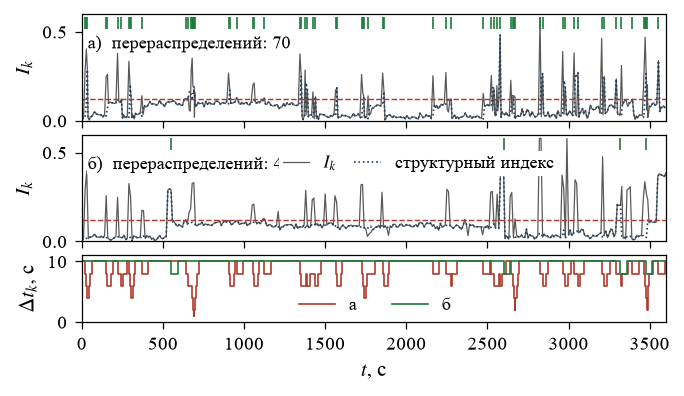

In [13]:
example = {key: simulate(loads[0], rules()[key](), trace=True)["trace"] for key in ("A", "E")}
a, b = 0, 3600
fig, axes = plt.subplots(3, 1, figsize=(11.5 * CM, 6.4 * CM), sharex=True,
                         gridspec_kw={"height_ratios": [1.6, 1.6, 1.0], "hspace": 0.15})
for ax, key, title in [(axes[0], "A", "а"), (axes[1], "E", "б")]:
    t = np.array(example[key]["t"])
    m = (t >= a) & (t <= b)
    ax.plot(t[m], np.array(example[key]["index"])[m], color=GRAY, lw=0.6, label="$I_k$")
    ax.plot(t[m], np.array(example[key]["structural"])[m], color=BLUE, lw=0.8, ls=":",
            label="структурный индекс")
    ax.axhline(UPPER, color=RED, ls="--", lw=0.7)
    f = np.array(example[key]["fired"], bool) & m
    ax.set_ylabel("$I_k$")
    ax.set_ylim(0, 0.6)
    ax.plot(t[f], np.full(f.sum(), 0.55), "|", color=GREEN, ms=6, mew=0.8)
    ax.text(0.01, 0.8, f"{title})  перераспределений: {int(f.sum())}", transform=ax.transAxes,
            va="top", fontsize=8.5, bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.5})
    if key == "E":
        ax.legend(loc="upper left", bbox_to_anchor=(0.335, 0.86), fontsize=8.5, ncol=2, handlelength=1.5,
                  borderaxespad=0.1, labelspacing=0.15, columnspacing=1.0, frameon=True, framealpha=1.0,
                  facecolor="white", edgecolor="none", borderpad=0.2)
for key, color in [("A", RED), ("E", GREEN)]:
    t = np.array(example[key]["t"])
    m = (t >= a) & (t <= b)
    axes[2].step(t[m], np.array(example[key]["interval"])[m], where="post", color=color, lw=0.8,
                 label="а" if key == "A" else "б")
axes[2].set_ylabel("$\\Delta t_k$, с")
axes[2].set_ylim(0, 11)
axes[2].set_xlabel("$t$, с")
axes[2].legend(loc="lower left", bbox_to_anchor=(0.36, 0.02), fontsize=8.5, ncol=2, borderaxespad=0.0)
for ax in axes:
    ax.set_xlim(a, b)
    ax.tick_params(labelsize=9)
fig.subplots_adjust(left=0.12, right=0.98, top=0.98, bottom=0.165)
plt.show()

## 5. Влияние выдержки и времени взведения

Правило Д ($T_c = 120$ с, $T_r = 300$ с) при выдержке $T_d$ от 0 до 90 с в вариантах (8а) и (8б),
затем правило Г ($T_d = 30$ с, $T_c = 120$ с) без взведения и с $T_r$ от 120 до 600 с.
Эти числа приведены в тексте статьи. Расчёт занимает несколько минут.

In [14]:
%%time
sweep = {"interval": [], "sample": []}
for mode in sweep:
    for dwell in (0.0, 10.0, 20.0, 30.0, 45.0, 60.0, 90.0):
        p = HysteresisParams(UPPER, LOWER, dwell, COOLDOWN, dwell_from=mode, rearm_after=REARM)
        s = summarize([simulate(load, Rule(p)) for load in loads])
        sweep[mode].append({"dwell": dwell, **{k: v["mean"] for k, v in s.items()}})

rearm = []
for tr in (None, 120.0, 180.0, 300.0, 600.0):
    p = HysteresisParams(UPPER, LOWER, DWELL, COOLDOWN, rearm_after=tr)
    s = summarize([simulate(load, Rule(p)) for load in loads])
    rearm.append({"rearm": tr, **{k: v["mean"] for k, v in s.items()}})

cols = {"total": "Решений", "false": "Ложных", "missed": "Пропущено эпизодов", "delay_median": "Медиана задержки, с"}
for mode, label in [("interval", "(8а)"), ("sample", "(8б)")]:
    print(f"Правило Д, отсчёт выдержки {label}")
    display(pd.DataFrame(sweep[mode]).set_index("dwell")[list(cols)].rename(columns=cols)
            .rename_axis("T_d, с").style.format("{:.1f}", decimal=","))
print("Правило Г с взведением по времени (9), T_d = 30 с, (8а)")
display(pd.DataFrame(rearm).assign(rearm=lambda d: d["rearm"].map(lambda x: "нет" if x is None else f"{x:.0f}"))
        .set_index("rearm")[list(cols)].rename(columns=cols).rename_axis("T_r, с").style.format("{:.1f}", decimal=","))

Правило Д, отсчёт выдержки (8а)


,Решений,Ложных,Пропущено эпизодов,"Медиана задержки, с"
"T_d, с",,,,
0.000000,"16,2","7,1","0,9","131,0"
10.000000,"16,2","7,1","0,9","131,0"
20.000000,"13,1","5,2","0,9","169,8"
30.000000,"9,0","2,4","0,7","124,8"
45.000000,"5,2","0,2","0,3","65,5"
60.000000,"4,9","0,1","0,4","69,4"
90.000000,"4,5","0,0","0,7","79,3"


Правило Д, отсчёт выдержки (8б)


,Решений,Ложных,Пропущено эпизодов,"Медиана задержки, с"
"T_d, с",,,,
0.000000,"16,2","7,1","0,9","131,0"
10.000000,"13,1","5,2","0,9","169,8"
20.000000,"9,0","2,4","0,7","124,8"
30.000000,"6,5","0,8","0,4","87,2"
45.000000,"4,9","0,1","0,4","69,4"
60.000000,"4,6","0,1","0,3","60,0"
90.000000,"4,4","0,0","0,5","89,3"


Правило Г с взведением по времени (9), T_d = 30 с, (8а)


,Решений,Ложных,Пропущено эпизодов,"Медиана задержки, с"
"T_r, с",,,,
nan,"3,1","1,2","1,6","641,0"
120,"12,2","3,0","0,2","83,4"
180,"10,7","2,8","0,4","93,7"
300,"9,0","2,4","0,7","124,8"
600,"6,8","2,0","1,0","181,9"


CPU times: user 1min 21s, sys: 479 ms, total: 1min 21s
Wall time: 1min 27s


Компромисс между числом ложных решений и задержкой реакции при изменении выдержки (этот график в статью
не вошёл, его выводы приведены в тексте числами):

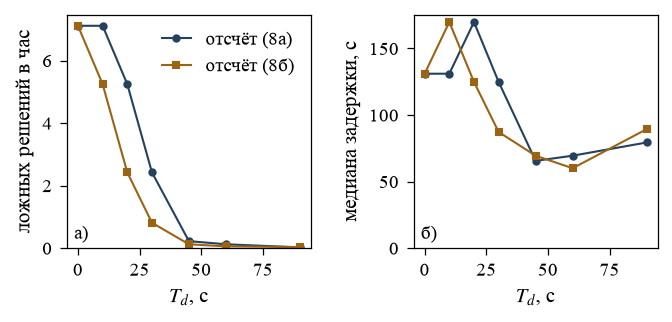

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.5 * CM, 5.2 * CM))
for mode, color, marker, label in [("interval", BLUE, "o", "отсчёт (8а)"), ("sample", ORANGE, "s", "отсчёт (8б)")]:
    rows = sweep[mode]
    td = [r["dwell"] for r in rows]
    axes[0].plot(td, [r["false"] for r in rows], color=color, marker=marker, ms=3, label=label)
    axes[1].plot(td, [r["delay_median"] for r in rows], color=color, marker=marker, ms=3, label=label)
axes[0].set_xlabel("$T_d$, с")
axes[0].set_ylabel("ложных решений в час")
axes[1].set_xlabel("$T_d$, с")
axes[1].set_ylabel("медиана задержки, с")
axes[0].legend(fontsize=9, loc="upper right", handlelength=1.5)
for ax, letter in zip(axes, "аб", strict=True):
    ax.tick_params(labelsize=9)
    ax.text(0.03, 0.04, f"{letter})", transform=ax.transAxes, fontsize=9)
    ax.set_ylim(bottom=0)
fig.subplots_adjust(left=0.11, right=0.98, top=0.97, bottom=0.21, wspace=0.42)
plt.show()

## 6. Отметки времени Unix и время обработки точки

Выдержка отсчитывается по (8) как разность $t_k - s_k$, а не накоплением суммы интервалов (4). При отметках
времени в формате Unix (около $1{,}7 \cdot 10^9$ с) и шаге 0,1 с накопление суммы из-за округления в арифметике
с плавающей точкой иногда достигает $T_d$ на шаг позже. Для $k = 1, \ldots, 600$ выдержка равна $k$ шагам,
и подсчитывается, в скольких рядах решение запаздывает.

In [16]:
def unix_boundary(cases: int = 600, dt: float = 0.1) -> dict:
    rng = np.random.default_rng(20261011)
    late_sum = late_lib = 0
    for k in range(1, cases + 1):
        t0 = float(rng.integers(1_600_000_000, 1_900_000_000))
        t = t0 + dt * np.arange(k + 2)
        dwell = k * dt
        acc, first = 0.0, None
        for i in range(1, t.size):
            acc += t[i] - t[i - 1]
            if acc >= dwell:
                first = i
                break
        late_sum += first != k
        h = Hysteresis(upper=UPPER, lower=LOWER, dwell=dwell, cooldown=0.0)
        fired = [h.step(1.0, float(x)).fired for x in t]
        late_lib += fired.index(True) != k
    return {"cases": cases, "dt": dt, "late_sum": late_sum, "late_lib": late_lib}


unix = unix_boundary()
print(f"запаздывание на шаг: накопление суммы (4) в {unix['late_sum']} из {unix['cases']} рядов, "
      f"библиотека в {unix['late_lib']} из {unix['cases']}")

запаздывание на шаг: накопление суммы (4) в 240 из 600 рядов, библиотека в 0 из 600


In [17]:
def cpu_name() -> str:
    try:
        with open("/proc/cpuinfo", encoding="utf-8") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


h = Hysteresis(upper=UPPER, lower=LOWER, dwell=DWELL, cooldown=COOLDOWN)
values = np.random.default_rng(1).uniform(0, 0.2, 200_000).tolist()
t0 = time.perf_counter()
for k, v in enumerate(values):
    h.step(v, float(k))
per_step_us = (time.perf_counter() - t0) / len(values) * 1e6
print(f"обработка одной точки: {per_step_us:.1f} мкс ({cpu_name()}, Python {platform.python_version()})")
print("в статье: 3,1 мкс (Intel Core i3-6006U, 2,0 ГГц, Python 3.14)")

обработка одной точки: 6.6 мкс (Intel(R) Core(TM) i3-6006U CPU @ 2.00GHz, Python 3.12.13)
в статье: 3,1 мкс (Intel Core i3-6006U, 2,0 ГГц, Python 3.14)


## 7. Сверка со статьёй

Числа, приведённые в тексте статьи и в табл. 1, сравниваются с полученными в ноутбуке после округления так же,
как в статье. Время обработки точки зависит от компьютера и здесь не сверяется.

In [18]:
by_dwell = {mode: {r["dwell"]: r for r in rows} for mode, rows in sweep.items()}
by_rearm = {r["rearm"]: r for r in rearm}
got = {}
for r in table:
    for k in ("total", "false", "useless", "episodes", "missed"):
        got[f"{r}.{k}"] = round(table[r][k]["mean"], 1)
    got[f"{r}.delay_median"] = round(table[r]["delay_median"]["mean"])
    got[f"{r}.points"] = round(table[r]["points"]["mean"])
got["A.total_std"] = round(table["A"]["total"]["std"], 1)
got["ratioB"] = round(table["A"]["total"]["mean"] / table["B"]["total"]["mean"])
for d in (30.0, 45.0):
    got[f"S{d:.0f}.false"] = round(by_dwell["interval"][d]["false"], 1)
    got[f"S{d:.0f}.delay_median"] = round(by_dwell["interval"][d]["delay_median"])
for tr in (120.0, 600.0):
    got[f"R{tr:.0f}.missed"] = round(by_rearm[tr]["missed"], 1)
    got[f"R{tr:.0f}.total"] = round(by_rearm[tr]["total"], 1)
got["unix.late_sum"] = unix["late_sum"]
got["unix.cases"] = unix["cases"]

ARTICLE = {
    "A.total": 339.5, "A.false": 36.9, "A.useless": 132.1, "A.episodes": 1.3, "A.missed": 0.0,
    "A.delay_median": 1, "A.points": 675, "A.total_std": 193.3,
    "A_timer.total": 12.2, "A_timer.false": 3.0, "A_timer.useless": 0.1, "A_timer.episodes": 3.4,
    "A_timer.missed": 0.2, "A_timer.delay_median": 83, "A_timer.points": 372,
    "B.total": 6.0, "B.false": 3.4, "B.useless": 0.0, "B.episodes": 2.6, "B.missed": 2.1,
    "B.delay_median": 884, "B.points": 366,
    "C.total": 3.3, "C.false": 1.3, "C.useless": 0.0, "C.episodes": 2.4, "C.missed": 1.6,
    "C.delay_median": 753, "C.points": 364,
    "D.total": 3.1, "D.false": 1.2, "D.useless": 0.0, "D.episodes": 2.4, "D.missed": 1.6,
    "D.delay_median": 641, "D.points": 363,
    "D_sample.total": 3.1, "D_sample.false": 0.4, "D_sample.useless": 0.0, "D_sample.episodes": 2.0,
    "D_sample.missed": 1.2, "D_sample.delay_median": 74, "D_sample.points": 363,
    "E.total": 9.0, "E.false": 2.4, "E.useless": 0.1, "E.episodes": 3.6, "E.missed": 0.7,
    "E.delay_median": 125, "E.points": 369,
    "E_sample.total": 6.5, "E_sample.false": 0.8, "E_sample.useless": 0.1, "E_sample.episodes": 2.2,
    "E_sample.missed": 0.4, "E_sample.delay_median": 87, "E_sample.points": 367,
    "ratioB": 56, "S30.false": 2.4, "S45.false": 0.2, "S30.delay_median": 125, "S45.delay_median": 66,
    "R120.missed": 0.2, "R120.total": 12.2, "R600.missed": 1.0, "R600.total": 6.8,
    "unix.late_sum": 240, "unix.cases": 600,
}
check = pd.DataFrame({"статья": ARTICLE, "ноутбук": {k: got[k] for k in ARTICLE}})
check["совпадает"] = check["статья"] == check["ноутбук"]
print(f"совпало {check['совпадает'].sum()} из {len(check)} чисел")
check[~check["совпадает"]] if not check["совпадает"].all() else None

совпало 68 из 68 чисел
